<div class="alert alert-block alert-success">

# Task 1 in Assessment 2
### Group 12: 

#### - Akhmad Fauzi Nurulhamzah
#### - [teammate]

Date: 10/11/2025

Environment: Python 3.13.7
</div>

<div class="alert alert-block alert-danger">
    
## Table of Contents

</div>

[1. Introduction](#Intro) <br>
[2. Importing Libraries](#Libs) <br>
[3. Load Data Files](#Load_Data) <br>
[4. Detect and fix errors in Group012_dirty_data.csv](#Dirty_Examine) <br>
$\;\;\;\;$[4.1. Column Check: date](#Dirty_date) <br>
$\;\;\;\;$[4.2. Column Check: order_type](#Dirty_order_type) <br>
$\;\;\;\;$[4.3. Column Check: branch_code](#Dirty_branch_code) <br>
$\;\;\;\;$[4.4. Column Check: order_items](#Dirty_order_items) <br>
$\;\;\;\;$[4.5. Column Check: order_price](#Dirty_order_price) <br>
$\;\;\;\;$[4.6. Column Check: customer_lat & customer_lon](#Dirty_coordinate) <br>
$\;\;\;\;$[4.7. Column Check: distance_to_customer_KM](#Dirty_distance) <br>
$\;\;\;\;$[4.8. Column Check: customerHasloyalty?](#Dirty_loyalty) <br>
$\;\;\;\;$[4.9. Output Dirty Data](#Dirty_output) <br>
[5. Detect and fix errors in Group012_missing_data.csv](#Dirty_Examine) <br>
$\;\;\;\;$[5.1. Column Check: branch_code](#Missing_branch_code) <br>
$\;\;\;\;$[5.2. Column Check: order_items & order_price](#Missing_order_items) <br>
$\;\;\;\;$[5.3. Column Check: distance_to_customer_KM & branch_code](#Missing_distance) <br>
$\;\;\;\;$[5.4. Column Check: delivery_fee](#Missing_delivery_fee) <br>
$\;\;\;\;$[5.5. Output Missing Data](#Missing_output) <br>
[6. Detect and remove outlier rows in Group012_outlier_data.csv](#Outlier_Examine) <br>
$\;\;\;\;$[6.1. Visual Inspection](#Outlier_visual) <br>
$\;\;\;\;$[6.2. Interquartile Range (IQR)](#Outlier_irq) <br>
$\;\;\;\;$[6.3. Box Plot](#Outlier_box_plot) <br>
$\;\;\;\;$[6.4. Delivery Fee Distribution with IQR Outlier](#Outlier_dis_iqr) <br>
$\;\;\;\;$[6.5. Z-Score](#Outlier_zscore_2) <br>
$\;\;\;\;$[6.6. Output Outlier Data](#Outlier_output) <br>
[7. Summary](#summary) <br>
[8. References](#Ref) <br>

-------------------------------------

<div class="alert alert-block alert-warning">

## 1. Introduction  <a class="anchor" name="Intro"></a>
    
</div>

In this assessment, we will write Python code to analyze the dataset, identify data quality issues, and apply fixes. The input files are: **Group012_dirty_data.csv**, **Group012_outlier_data.csv**, **Group012_missing_data.csv**, **branches.csv**, **edges.csv**, and **nodes.csv**. The deliverable is a set of cleaned CSV files produced from these inputs.

---

<div class="alert alert-block alert-warning">
    
## 2.  Importing Libraries  <a class="anchor" name="Libs"></a>

</div>

The packages to be used in this assessment are imported in the following. They are used to fulfill the following tasks:

* **pandas**: Data manipulation, handle and preprocess tabular data
* **numpy**: Numerical computation, underlying math for data and ML
* **ast**: Parsing, convert order strings into structured lists
* **networkx**: Graph analysis, model delivery networks & compute distances
* **datetime**: Date/time handling, extract weekend flags from dates
* **sklearn.linear_model**: ML model, fit linear regression models
* **train_test_split**: ML utility, split data into train/test sets
* **r2_score**: Evaluation, measure model performance
* **matplotlib.pyplot**: Visualization, plot model results and data trends




In [1]:
import pandas as pd
import numpy as np
import ast
import networkx as nx
from datetime import datetime
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

---

<div class="alert alert-block alert-warning">

## 3. Load Data Files  <a class="anchor" name="Load_Data"></a>

</div>

In this section, we will open and read all the CSV files required for this assignment. All the CSV files are stored in the same directory as the main program.

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

dirty_csv_filename = "Group012_dirty_data.csv"
missing_csv_filename = "Group012_missing_data.csv"
outlier_csv_filename = "Group012_outlier_data.csv"
branches_filename = "branches.csv"
edges_filename = "edges.csv"
nodes_filename = "nodes.csv"

# Read the dirty csv file
df_dirty = pd.read_csv(dirty_csv_filename, encoding="utf-8", low_memory=False)

# Initialize with 'original' to mark current data before cleaning
df_dirty["status"] = "original"

# Display the result
print(dirty_csv_filename + ": ")
display(df_dirty[['order_id', 'date', 'order_type', 'order_items', 'order_price', 'delivery_fee']].head(5))

print("-"*100)

# Read the missing csv file
df_missing = pd.read_csv(missing_csv_filename, encoding="utf-8", low_memory=False)

# Initialize with 'original' to mark current data before cleaning
df_missing["status"] = "original"

# Display the result
print(missing_csv_filename + ": ")
display(df_missing[['order_id', 'date', 'order_type', 'order_items', 'order_price', 'delivery_fee']].head(5))

print("-"*100)

# Read the outlier csv file
df_outlier = pd.read_csv(outlier_csv_filename, encoding="utf-8", low_memory=False)

# Initialize with 'original' to mark current data before cleaning
df_outlier["status"] = "original"

# Display the result
print(outlier_csv_filename + ": ")
display(df_outlier[['order_id', 'date', 'order_type', 'order_items', 'order_price', 'delivery_fee']].head(5))

# Read the branches_filename csv file
df_branches = pd.read_csv(branches_filename, encoding="utf-8", low_memory=False)

# Read the edges_filename csv file
df_edges = pd.read_csv(edges_filename, encoding="utf-8", low_memory=False)

# Read the nodes_filename csv file
df_nodes = pd.read_csv(nodes_filename, encoding="utf-8", low_memory=False)

Group012_dirty_data.csv: 


,order_id,date,order_type,order_items,order_price,delivery_fee
0,ORDZ07402,2018-07-07,Lunch,"[('Fries', 3), ('Steak', 10), ('Salad', 5)]",572.0,17.942118
1,ORDJ10221,2018-10-31,Dinner,"[('Shrimp', 8), ('Fish&Chips', 6), ('Salmon', 6)]",888.0,14.445349
2,ORDI03102,2018-05-03,Lunch,"[('Steak', 6), ('Burger', 2), ('Fries', 4), ('...",517.6,13.157205
3,ORDI09202,2018-03-10,Breakfast,"[('Eggs', 1), ('Cereal', 4)]",106.0,16.171184
4,ORDZ05433,2018-08-05,Lunch,"[('Chicken', 10), ('Burger', 6), ('Eggs', 9), ...",856.2,16.187008


----------------------------------------------------------------------------------------------------
Group012_missing_data.csv: 


,order_id,date,order_type,order_items,order_price,delivery_fee
0,ORDA00511,2018-08-29,Lunch,"[('Burger', 7), ('Chicken', 5), ('Salad', 7), ...",602.40,NaN
1,ORDJ01425,2018-10-15,Dinner,"[('Pasta', 1), ('Shrimp', 1)]",81.50,14.609857
2,ORDB05222,2018-04-17,Breakfast,"[('Coffee', 3), ('Cereal', 2), ('Eggs', 2), ('...",278.25,12.130384
3,ORDA08774,2018-11-09,Dinner,"[('Pasta', 9), ('Shrimp', 7), ('Salmon', 9), (...",1309.50,NaN
4,ORDY08459,2018-07-30,Lunch,"[('Burger', 8), ('Fries', 9), ('Chicken', 4)]",484.00,13.774208


----------------------------------------------------------------------------------------------------
Group012_outlier_data.csv: 


,order_id,date,order_type,order_items,order_price,delivery_fee
0,ORDK02730,2018-06-10,Lunch,"[('Steak', 6), ('Burger', 2), ('Salad', 3), ('...",467.6,16.079865
1,ORDK10554,2018-08-24,Lunch,"[('Chicken', 2), ('Salad', 5)]",150.0,13.892975
2,ORDJ00507,2018-02-12,Breakfast,"[('Pancake', 10), ('Coffee', 8), ('Eggs', 3), ...",515.5,15.053920
3,ORDA04326,2018-11-28,Dinner,"[('Salmon', 8), ('Pasta', 4)]",438.0,13.817187
4,ORDA11032,2018-06-27,Lunch,"[('Fries', 10), ('Steak', 8), ('Salad', 7), ('...",728.4,12.467202


-------------------------------------

<div class="alert alert-block alert-warning">

## 4. Detect and fix errors in Group012_dirty_data.csv <a class="anchor" name="Dirty_Examine"></a>

</div>

To ensure that all columns match the required format as described in the assignment instructions:

1. **date:** Verify that the date format follows the YYYY-MM-DD pattern, representing the date when the order was made.
2. **order_type:** Check that the category values are correctly labeled as Breakfast, Lunch, or Dinner, and ensure capitalization is consistent.
3. **branch_code:** Confirm that values are limited to the three valid branches: Nickolson (NS), Thompson (TP), and Bakers (BK).
4. **order_items:** Check for any inconsistencies between the items ordered and their corresponding order_type. According to the assignment, only specific items are available for each meal type (e.g., breakfast items cannot be served during lunch or dinner).
5. **order_price:** Ensure that the values are floats representing the total price of the order. Check for potential pricing errors (e.g., an incorrect item price may result in an inaccurate total order_price).
6. **customer_lat & customer_lon:** Validate by cross-checking the coordinates with the nodes.csv file.
7. **distance_to_customer_KM:** Calculate the distance from branch to customer using Dijkstra’s algorithm via the networkx package.
8. **customerHasloyalty?:** Is the price is right based on formula

-------------------------------------

<div class="alert alert-block alert-info">
    
### 4.1. Column Check: date <a class="anchor" name="Dirty_date"></a>

</div>

In this section, we will verify that the date column follows the **YYYY-MM-DD** format, representing the date when the order was made.

In [3]:
# Check current format by trying to convert to datetime
df_dirty["date_converted"] = pd.to_datetime(df_dirty["date"], format="%Y-%m-%d", errors="coerce")

# Find rows where conversion failed (invalid date format)
invalid_date_mask = df_dirty["date_converted"].isna() & df_dirty["date"].notna()
invalid_dates = df_dirty[invalid_date_mask]

# Show invalid date examples
if not invalid_dates.empty:
    display(invalid_dates[["order_id", "date"]].head(10))
else:
    print("All date values follow the YYYY-MM-DD format.")

print(f"Total invalid date format rows: {invalid_date_mask.sum()}")

,order_id,date
7,ORDX00678,12-05-2018
9,ORDB09643,2018-28-09
11,ORDJ01273,05-05-2018
14,ORDZ04867,01-07-2018
32,ORDX03089,2018-16-12
39,ORDZ10598,07-12-2018
46,ORDB01308,11-12-2018
56,ORDY05398,2018-16-12
77,ORDI02223,04-07-2018
115,ORDY07234,11-11-2018


Total invalid date format rows: 37


---
From the date check, we found that **37** rows have an incorrect date format. Through manual inspection, we identified that the errors were caused by inconsistent formatting, such as using **DD-MM-YYYY** or **YYYY-DD-MM** instead of the correct **YYYY-MM-DD format**. In the next step, we will fix the incorrect date formats and record the details in the status column.

In [4]:
# For rows where date_converted is empty (NaT), try DD-MM-YYYY
mask_empty = df_dirty["date_converted"].isna() & df_dirty["date"].notna()
parsed_ddmmyyyy = pd.to_datetime(df_dirty.loc[mask_empty, "date"], format="%d-%m-%Y", errors="coerce")

success_dd = parsed_ddmmyyyy.notna()
idx_dd = parsed_ddmmyyyy[success_dd].index

# Update converted dates
df_dirty.loc[idx_dd, "date_converted"] = parsed_ddmmyyyy.loc[idx_dd]

# Update status: wrong date format DD-MM-YYYY
df_dirty.loc[idx_dd, "status"] = (
    'Wrong date format DD-MM-YYYY, before "' 
    + df_dirty.loc[idx_dd, "date"].astype(str) 
    + '" after "' 
    + df_dirty.loc[idx_dd, "date_converted"].dt.strftime("%Y-%m-%d") 
    + '"'
)

# Count the update
print(f"Repaired (DD-MM-YYYY): {len(idx_dd)} rows")

# For remaining empties, try YYYY-DD-MM
mask_empty = df_dirty["date_converted"].isna() & df_dirty["date"].notna()
parsed_yyyyddmm = pd.to_datetime(df_dirty.loc[mask_empty, "date"], format="%Y-%d-%m", errors="coerce")

success_ydm = parsed_yyyyddmm.notna()
idx_ydm = parsed_yyyyddmm[success_ydm].index

# Update converted dates
df_dirty.loc[idx_ydm, "date_converted"] = parsed_yyyyddmm.loc[idx_ydm]

# Update status: wrong date format YYYY-DD-MM
df_dirty.loc[idx_ydm, "status"] = (
    'Wrong date format YYYY-DD-MM, before "' 
    + df_dirty.loc[idx_ydm, "date"].astype(str) 
    + '" after "' 
    + df_dirty.loc[idx_ydm, "date_converted"].dt.strftime("%Y-%m-%d") 
    + '"'
)

# Count the update
print(f"Repaired (YYYY-DD-MM): {len(idx_ydm)} rows")

# Update 'date' with the successfully converted values in YYYY-MM-DD format
has_converted = df_dirty["date_converted"].notna()
df_dirty.loc[has_converted, "date"] = df_dirty.loc[has_converted, "date_converted"].dt.strftime("%Y-%m-%d")

# Drop the column 'date_converted' from df_dirty
df_dirty.drop(columns=["date_converted"], inplace=True)

Repaired (DD-MM-YYYY): 18 rows
Repaired (YYYY-DD-MM): 19 rows


---

<div class="alert alert-block alert-info">
    
### 4.2. Column Check: order_type<a class="anchor" name="Dirty_order_type"></a>

</div>

In this section, we will check the **order_type** data. There are three meal categories based on the time the order was made:

- **Breakfast:** served in the morning (8:00 AM – 12:00 PM)
- **Lunch:** served in the afternoon (12:00:01 PM – 4:00 PM)
- **Dinner:** served in the evening (4:00:01 PM – 8:00 PM)

In [5]:
# Create function to get order_type by time
def get_order_type(row):
    try:
        # convert string time to datetime.time
        t = datetime.strptime(row['time'], "%H:%M:%S").time()
    except Exception:
        return None
    
    # classify based on given time ranges
    if datetime.strptime("08:00:00", "%H:%M:%S").time() <= t <= datetime.strptime("12:00:00", "%H:%M:%S").time():
        return "Breakfast"
    elif datetime.strptime("12:00:01", "%H:%M:%S").time() <= t <= datetime.strptime("16:00:00", "%H:%M:%S").time():
        return "Lunch"
    elif datetime.strptime("16:00:01", "%H:%M:%S").time() <= t <= datetime.strptime("20:00:00", "%H:%M:%S").time():
        return "Dinner"
    else:
        return "Other"

# apply to dataframe
df_dirty['new_order_type'] = df_dirty.apply(get_order_type, axis=1)

# Filter for update order_type
filter_new_order_type = df_dirty['new_order_type'] != df_dirty['order_type']

# Update status for tracking
df_dirty.loc[filter_new_order_type, "status"] = (
    'Wrong order_type, before "' 
    + df_dirty['order_type'] 
    + '" after "' 
    + df_dirty['new_order_type'] 
    + '"'
)

# Show edited data
display(df_dirty.loc[filter_new_order_type, ['order_id', 'order_type', 'new_order_type', 'status']].head(10))

# Count the updated row
print(f"Repaired order_type: {filter_new_order_type.sum()} rows")

# Update order_type
df_dirty.loc[filter_new_order_type, "order_type"] = df_dirty.loc[filter_new_order_type, "new_order_type"]

# Drop the column 'new_order_type' from df_dirty
df_dirty.drop(columns=["new_order_type"], inplace=True)

,order_id,order_type,new_order_type,status
12,ORDA06125,Dinner,Lunch,"Wrong order_type, before ""Dinner"" after ""Lunch"""
15,ORDA01778,Breakfast,Dinner,"Wrong order_type, before ""Breakfast"" after ""Di..."
59,ORDA02301,Lunch,Breakfast,"Wrong order_type, before ""Lunch"" after ""Breakf..."
66,ORDX06835,Dinner,Breakfast,"Wrong order_type, before ""Dinner"" after ""Break..."
79,ORDC07697,Breakfast,Lunch,"Wrong order_type, before ""Breakfast"" after ""Lu..."
91,ORDK04033,Dinner,Lunch,"Wrong order_type, before ""Dinner"" after ""Lunch"""
92,ORDZ01114,Dinner,Lunch,"Wrong order_type, before ""Dinner"" after ""Lunch"""
109,ORDI09511,Lunch,Dinner,"Wrong order_type, before ""Lunch"" after ""Dinner"""
111,ORDJ07614,Breakfast,Dinner,"Wrong order_type, before ""Breakfast"" after ""Di..."
125,ORDI04764,Breakfast,Lunch,"Wrong order_type, before ""Breakfast"" after ""Lu..."


Repaired order_type: 37 rows


---

<div class="alert alert-block alert-info">

### 4.3. Column Check: branch_code <a class="anchor" name="Dirty_branch_code"></a>

</div>

In this section, we will confirm that the **branch_code** values are limited to the three valid branches: **Nickolson (NS)**, **Thompson (TP)**, and **Bakers (BK)**.

In [6]:
# Get the unique data for branch
unique_branch_codes = df_dirty["branch_code"].astype(str).str.strip().unique()

print("Distinct values in 'branch_code':")
for val in unique_branch_codes:
    print("-", repr(val))

print(f"\nTotal unique values: {len(unique_branch_codes)}")

Distinct values in 'branch_code':
- 'NS'
- 'TP'
- 'BK'
- 'bk'
- 'ns'
- 'tp'

Total unique values: 6


---
From this check, we found that there are three branch_code values that are incorrect: **'bk', 'ns', and 'tp'** which are written in lowercase. The correct values should be in uppercase: **'BK', 'NS', and 'TP'**.

In [7]:
# Identify rows with lowercase branch_code
lowercase_mask = df_dirty["branch_code"].isin(["ns", "tp", "bk"])

# Update status with before/after info
df_dirty.loc[lowercase_mask, "status"] = (
    'wrong branch_code (lowercase), before "'
    + df_dirty.loc[lowercase_mask, "branch_code"]
    + '" after "'
    + df_dirty.loc[lowercase_mask, "branch_code"].str.upper()
    + '"'
)

# Show edited data
display(df_dirty.loc[lowercase_mask, ['order_id', 'branch_code', 'status']].head(10))

# Count many updated row
print(f"Repaired branch_code: {lowercase_mask.sum()} rows with lowercase branch_code.")

# Convert lowercase values to uppercase (NS, TP, BK)
df_dirty.loc[lowercase_mask, "branch_code"] = df_dirty.loc[lowercase_mask, "branch_code"].str.upper()

,order_id,branch_code,status
30,ORDA07493,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
34,ORDB02606,ns,"wrong branch_code (lowercase), before ""ns"" aft..."
41,ORDY03556,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
58,ORDK02490,ns,"wrong branch_code (lowercase), before ""ns"" aft..."
137,ORDK09867,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
146,ORDI00895,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
165,ORDI08018,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
168,ORDZ05019,bk,"wrong branch_code (lowercase), before ""bk"" aft..."
190,ORDJ05998,ns,"wrong branch_code (lowercase), before ""ns"" aft..."
204,ORDC07640,ns,"wrong branch_code (lowercase), before ""ns"" aft..."


Repaired branch_code: 24 rows with lowercase branch_code.


---

<div class="alert alert-block alert-info">
    
### 4.4. Column Check: order_items <a class="anchor" name="Dirty_order_items"></a>

</div>

#### Step 1: Get the Correct Items for Each Order Type

As mentioned in the assignment, there are no data anomalies in the file **Group012_outlier_data.csv**, so we can safely create the list of items for each order_type based on this dataset.


In [8]:
# Helper function to parsing each row of data
def parse_order_items(val):
    if pd.isna(val):
        return []
    s = str(val).strip()
    if not s:
        return []
    try:
        obj = ast.literal_eval(s)
        items = []
        if isinstance(obj, (list, tuple)):
            for entry in obj:
                if isinstance(entry, (list, tuple)) and len(entry) >= 1:
                    name = entry[0]
                    if isinstance(name, str) and name.strip():
                        items.append(name.strip())
                elif isinstance(entry, str) and entry.strip():
                    items.append(entry.strip())
        return items
    except Exception:
        return []

# Build catalog of allowed items per order_type from df_ref
ref_types = ["Breakfast", "Lunch", "Dinner"]
items_by_type = {t: set() for t in ref_types}
item_to_types = {}

for _, r in df_outlier.iterrows():
    t = r.get("order_type")
    if t not in ref_types:
        continue
    names = parse_order_items(r.get("order_items"))
    for name in names:
        items_by_type[t].add(name)
        item_to_types.setdefault(name, set()).add(t)

print("Type for Each Item:")
print(item_to_types)

print("---")
print("Item for Each Type:")
print(items_by_type)

Type for Each Item:
{'Steak': {'Lunch'}, 'Burger': {'Lunch'}, 'Salad': {'Lunch'}, 'Fries': {'Lunch'}, 'Chicken': {'Lunch'}, 'Pancake': {'Breakfast'}, 'Coffee': {'Breakfast'}, 'Eggs': {'Breakfast'}, 'Cereal': {'Breakfast'}, 'Salmon': {'Dinner'}, 'Pasta': {'Dinner'}, 'Fish&Chips': {'Dinner'}, 'Shrimp': {'Dinner'}}
---
Item for Each Type:
{'Breakfast': {'Eggs', 'Cereal', 'Coffee', 'Pancake'}, 'Lunch': {'Chicken', 'Fries', 'Burger', 'Salad', 'Steak'}, 'Dinner': {'Pasta', 'Fish&Chips', 'Salmon', 'Shrimp'}}


---

#### Step 2: Get the Wrong Order Items

To retrieve information about **wrong order items**, we compare each row’s **order_items** with its corresponding **order_type**. If a mismatch is found between the order_items and the order_type, we will record the details of the item that does not match the assigned order_type.

In [9]:
# Get the wrong items
def row_bad_items(row):
    t = row.get("order_type")
    names = parse_order_items(row.get("order_items"))

    if t not in items_by_type:
        # unknown type -> treat all parsed items as bad
        return names
        
    allowed = items_by_type[t]

    return [item for item in names if item and item not in allowed]

# Get the wrong item that does not match the order_type
df_dirty['bad_item_list'] = df_dirty.apply(row_bad_items, axis=1)

# Count how many error
df_dirty['bad_item_length'] = df_dirty['bad_item_list'].str.len()

# Show error data
display(df_dirty.loc[df_dirty['bad_item_length'] > 0, ['order_id', 'order_type', 'order_items', 'bad_item_list', 'bad_item_length']].head(10))

,order_id,order_type,order_items,bad_item_list,bad_item_length
4,ORDZ05433,Lunch,"[('Chicken', 10), ('Burger', 6), ('Eggs', 9), ...",[Eggs],1
17,ORDI07692,Lunch,"[('Cereal', 1), ('Fries', 5)]",[Cereal],1
25,ORDJ07313,Dinner,"[('Fish&Chips', 10), ('Eggs', 1)]",[Eggs],1
29,ORDC00069,Dinner,"[('Shrimp', 6), ('Burger', 2)]",[Burger],1
64,ORDX09678,Breakfast,"[('Pancake', 1), ('Fish&Chips', 1), ('Cereal',...",[Fish&Chips],1
73,ORDB01516,Dinner,"[('Eggs', 9), ('Fish&Chips', 2)]",[Eggs],1
76,ORDY04003,Dinner,"[('Pasta', 1), ('Salad', 7)]",[Salad],1
132,ORDY05593,Lunch,"[('Pancake', 6), ('Salad', 5), ('Steak', 6)]",[Pancake],1
153,ORDZ02430,Lunch,"[('Salmon', 7), ('Chicken', 1)]",[Salmon],1
176,ORDJ03283,Breakfast,"[('Coffee', 6), ('Eggs', 3), ('Chicken', 10)]",[Chicken],1


---

#### Step 3: Analyze and Identify Each Item’s Price

Before moving to the next process, we need to determine the price of each item. This information can be obtained from the **Group012_outlier_data.csv** file, which according to the assignment, contains no errors. To calculate the unit price of each item, we can use the **NumPy library** specifically, the **numpy.linalg** package, which is useful for solving multivariable equations.

In [10]:
# Function to parse the string into list
def parse_order_items(val):
    if pd.isna(val):
        return []
    s = str(val).strip()
    if not s:
        return []
    try:
        obj = ast.literal_eval(s)
        out = []
        if isinstance(obj, (list, tuple)):
            for tup in obj:
                if isinstance(tup, (list, tuple)) and len(tup) >= 2:
                    name, qty = tup[0], tup[1]
                    if isinstance(name, str) and str(qty).strip() != "":
                        out.append((name.strip(), float(qty)))
        return out
    except Exception:
        return []

# Build list of items from the reference dataset
ref_items_parsed = df_outlier["order_items"].apply(parse_order_items)

all_items = sorted({name for row in ref_items_parsed for name, _ in row})

print("All Items on Outlier data:")
print(all_items)

item_to_idx = {name: i for i, name in enumerate(all_items)}

n_items = len(all_items)

# Build linear system A x = b
# A: rows = orders, cols = items, entries = quantity of item in that order
# b: total order_price
rows = []
b = []
for (_, row), items in zip(df_outlier.iterrows(), ref_items_parsed):
    vec = np.zeros(n_items, dtype=float)
    for name, qty in items:
        if name in item_to_idx:
            vec[item_to_idx[name]] += float(qty)
    rows.append(vec)
    b.append(float(row["order_price"]))

A = np.vstack(rows) if rows else np.zeros((0, n_items))

print("-"*75)
print("A")
print(A[:5])

b = np.array(b, dtype=float)

print("-"*75)
print("b")
print(b[:5])

# Solve for unit prices with least squares
x, residuals, rank, svals = np.linalg.lstsq(A, b, rcond=None)

print("-"*75)
print("x")
print(x)

x = np.round(x, decimals=2)

print("-"*75)
print(f'Residuals: {residuals}, Rank: {rank}')

unit_prices = pd.Series(x, index=all_items)

print("-"*75)
print("unit_prices")
print(unit_prices)

All Items on Outlier data:
['Burger', 'Cereal', 'Chicken', 'Coffee', 'Eggs', 'Fish&Chips', 'Fries', 'Pancake', 'Pasta', 'Salad', 'Salmon', 'Shrimp', 'Steak']
---------------------------------------------------------------------------
A
[[ 2.  0.  0.  0.  0.  0.  7.  0.  0.  3.  0.  0.  6.]
 [ 0.  0.  2.  0.  0.  0.  0.  0.  0.  5.  0.  0.  0.]
 [ 0.  7.  0.  8.  3.  0.  0. 10.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  4.  0.  8.  0.  0.]
 [ 0.  0.  4.  0.  0.  0. 10.  0.  0.  7.  0.  0.  8.]]
---------------------------------------------------------------------------
b
[467.6 150.  515.5 438.  728.4]
---------------------------------------------------------------------------
x
[31.   21.   32.    7.5  22.   35.   12.   24.25 27.5  17.2  41.   54.
 45.  ]
---------------------------------------------------------------------------
Residuals: [3.00578099e-24], Rank: 13
---------------------------------------------------------------------------
unit_prices
Burger        31.00

---

#### Step 4: Identify the Incorrect Order Item

Based on the assignment information stating that all anomalies in the dirty data have one and only one possible fix per row, this means that the item is the only possible error within that row. Now, let’s proceed with a deeper analysis of the data.

In [11]:
display(df_dirty.loc[df_dirty['bad_item_length'] == 1, ['order_id', 'order_type', 'order_items', 'bad_item_list', 'order_price']].head(5))

,order_id,order_type,order_items,bad_item_list,order_price
4,ORDZ05433,Lunch,"[('Chicken', 10), ('Burger', 6), ('Eggs', 9), ...",[Eggs],856.20
17,ORDI07692,Lunch,"[('Cereal', 1), ('Fries', 5)]",[Cereal],92.00
25,ORDJ07313,Dinner,"[('Fish&Chips', 10), ('Eggs', 1)]",[Eggs],391.00
29,ORDC00069,Dinner,"[('Shrimp', 6), ('Burger', 2)]",[Burger],394.00
64,ORDX09678,Breakfast,"[('Pancake', 1), ('Fish&Chips', 1), ('Cereal',...",[Fish&Chips],172.25


---

Lets analyze the data 

- **order_id**      : ORDZ05433  
- **order_items**   : [('Chicken', 10), ('Burger', 6), ('Eggs', 9), ('Steak', 5), ('Salad', 1)]
- **order_price**   : 856.2
- **bad_item_list** : ['Eggs']

Based on our previous checks, the incorrect item in this order is **Eggs**.

Let’s verify the order_price using the given order_items (**Eggs** subtitute with **x**):

- (Chicken * 10) + (Burger * 6) + (x * 9) + (Steak * 5) + (Salad * 1) = 856.2
- (32.00 * 10) + (31.00 * 6) + (x * 9) + (45.00 * 5) + (17.20 * 1) = 856.2
- 320 + 186 + (x * 9) + 225 + 17.2 = 856.2
- x * 9 = 108
- x = 12

Based on this calculation, the most likely item corresponding to x = 12 is **Fries**, which has a unit price of **12** and it has **order_type** is **Lunch** which is inline with its order_type.

**Reference Data:**

**Item price:**
- Burger = 31.00,
- Cereal = 21.00,
- Chicken = 32.00,
- Coffee = 7.50,
- Eggs = 22.00,
- Fish&Chips = 35.00,
- Fries = 12.00,
- Pancake = 24.25,
- Pasta = 27.50,
- Salad = 17.20,
- Salmon = 41.00,
- Shrimp = 54.00,
- Steak = 45.00

**order_type:**

- 'Breakfast': {'Cereal', 'Eggs', 'Coffee', 'Pancake'},
- 'Lunch': {'Salad', 'Steak', 'Chicken', 'Burger', 'Fries'},
- 'Dinner': {'Salmon', 'Pasta', 'Shrimp', 'Fish&Chips'}

**Conclusion:**

Based on this test, we believe that this method can be effectively used to identify incorrect order items.


In [12]:
# Build list of items from the reference dataset
df_dirty["order_items_list"] = df_dirty["order_items"].apply(parse_order_items)

# Get the wrong item price
def get_unknown_item_price(row):
    bi_length = row.get("bad_item_length")

    if bi_length == 1:

        oi_list = row.get("order_items_list")
        o_price = row.get("order_price")
        bad_item = row.get("bad_item_list")[0]
        remainder = o_price
        bad_item_divider = 1;
        
        for item_name, total in oi_list:
            if item_name == bad_item:
                bad_item_divider =total
            else:
                remainder -= unit_prices[item_name]*total

        unknown_item_price = round(remainder / bad_item_divider, 2)
        return unknown_item_price         
    return 0

# Get Item name by its price
def get_unknown_item_name(row):
    bi_length = row.get("bad_item_length")
    ui_price = row.get("unknown_item_price")

    if bi_length == 1:        
        item_name = unit_prices[np.isclose(unit_prices, ui_price)].index[0]        
        return item_name 
    return ''

# Update order_items data
def update_order_item(row):
    bi_length = row.get("bad_item_length")
    order_items = row.get("order_items")   

    if bi_length == 1:
        bad_item = row.get("bad_item_list")[0]
        right_item = row.get("right_item_name")

        return order_items.replace(bad_item, right_item)

    return order_items

# Get the price of unknown item
df_dirty['unknown_item_price'] = df_dirty.apply(get_unknown_item_price, axis=1)

# Get item name from the price
df_dirty['right_item_name'] = df_dirty.apply(get_unknown_item_name, axis=1)

# Update the with the right data
df_dirty['order_items'] = df_dirty.apply(update_order_item, axis=1)

# Make filter for wrong item
filter_new_order_item = df_dirty['bad_item_length'] == 1

# Update status
df_dirty.loc[filter_new_order_item, "status"] = (
    'Wrong order_items, before "' 
    + df_dirty['bad_item_list'].str.get(0)
    + '" after "' 
    + df_dirty['right_item_name'] 
    + '"'
)

display(df_dirty.loc[df_dirty['bad_item_length'] == 1, ['order_id', 'order_type', 'order_items', 'bad_item_list', 'unknown_item_price', 'right_item_name']].head(10))

# Count the updated row
print(f"Repaired order_items: {filter_new_order_item.sum()} rows")

# Drop the column 'new_order_type' from df_dirty
df_dirty.drop(columns=["bad_item_list"], inplace=True)
df_dirty.drop(columns=["bad_item_length"], inplace=True)
df_dirty.drop(columns=["unknown_item_price"], inplace=True)
df_dirty.drop(columns=["right_item_name"], inplace=True)
df_dirty.drop(columns=["order_items_list"], inplace=True)

,order_id,order_type,order_items,bad_item_list,unknown_item_price,right_item_name
4,ORDZ05433,Lunch,"[('Chicken', 10), ('Burger', 6), ('Fries', 9),...",[Eggs],12.00,Fries
17,ORDI07692,Lunch,"[('Chicken', 1), ('Fries', 5)]",[Cereal],32.00,Chicken
25,ORDJ07313,Dinner,"[('Fish&Chips', 10), ('Salmon', 1)]",[Eggs],41.00,Salmon
29,ORDC00069,Dinner,"[('Shrimp', 6), ('Fish&Chips', 2)]",[Burger],35.00,Fish&Chips
64,ORDX09678,Breakfast,"[('Pancake', 1), ('Eggs', 1), ('Cereal', 6)]",[Fish&Chips],22.00,Eggs
73,ORDB01516,Dinner,"[('Salmon', 9), ('Fish&Chips', 2)]",[Eggs],41.00,Salmon
76,ORDY04003,Dinner,"[('Pasta', 1), ('Salmon', 7)]",[Salad],41.00,Salmon
132,ORDY05593,Lunch,"[('Fries', 6), ('Salad', 5), ('Steak', 6)]",[Pancake],12.00,Fries
153,ORDZ02430,Lunch,"[('Steak', 7), ('Chicken', 1)]",[Salmon],45.00,Steak
176,ORDJ03283,Breakfast,"[('Coffee', 6), ('Eggs', 3), ('Pancake', 10)]",[Chicken],24.25,Pancake


Repaired order_items: 37 rows


---

<div class="alert alert-block alert-info">
    
### 4.5. Column Check: order_price <a class="anchor" name="Dirty_order_price"></a>

</div>

Based on the previous check, we already know the price of each item. In this section, we will validate the **order_price** by comparing it with the corresponding item prices to identify which rows contain invalid values.

In [13]:
# Build list of items from the reference dataset
# We do this again because now the order_items already updated with the right data
df_dirty["order_items_list"] = df_dirty["order_items"].apply(parse_order_items)

# Calculate the new price
def calculate_order_price(row):
    oi_list = row.get("order_items_list")

    total_price = 0;    
    for item_name, total in oi_list:

        total_price += unit_prices[item_name] * total

    rounded = int(round(total_price*100))
    return rounded/100

# Compare data with calculated price
def check_bad_price(row):
    return np.isclose(row.get("order_price"), row.get("new_order_price"))

# Calculate new order_price
df_dirty['new_order_price'] = df_dirty.apply(calculate_order_price, axis=1)

# Make boolen which row that wrong price
df_dirty['bad_price'] = df_dirty.apply(check_bad_price, axis=1)

# Crete filter that have wrong price
filter_bad_price = ~df_dirty['bad_price']

# Update status
df_dirty.loc[filter_bad_price, "status"] = (
    'Wrong order_price, before "' 
    + df_dirty['order_price'].astype(str)
    + '" after "' 
    + df_dirty['new_order_price'].astype(str)
    + '"'
)

# Show edited data
display(df_dirty.loc[filter_bad_price, ['order_id', 'order_items', 'order_price', 'new_order_price']].head(10))

# Count the updated row
print(f"Repaired order_price: {filter_bad_price.sum()} rows")

# Update Data
df_dirty.loc[filter_bad_price, "order_price"] = df_dirty['new_order_price']

# Drop the column from df_dirty
df_dirty.drop(columns=["order_items_list"], inplace=True)
df_dirty.drop(columns=["new_order_price"], inplace=True)
df_dirty.drop(columns=["bad_price"], inplace=True)


,order_id,order_items,order_price,new_order_price
6,ORDB01126,"[('Pasta', 6), ('Fish&Chips', 6), ('Shrimp', 1...",872.6,1325.00
44,ORDJ07174,"[('Fries', 2), ('Burger', 4)]",217.4,148.00
47,ORDJ09320,"[('Salmon', 7), ('Pasta', 8), ('Fish&Chips', 1...",1053.5,1289.00
65,ORDY09334,"[('Fries', 4), ('Burger', 10), ('Chicken', 4),...",133.0,711.00
78,ORDC08542,"[('Pancake', 1), ('Eggs', 3), ('Coffee', 4)]",251.4,120.25
113,ORDK03441,"[('Salad', 8), ('Chicken', 10), ('Fries', 7), ...",369.5,586.60
114,ORDB05699,"[('Fries', 3), ('Burger', 10), ('Chicken', 5)]",786.0,506.00
152,ORDZ09972,"[('Salad', 8), ('Chicken', 3), ('Steak', 8), (...",357.0,872.60
170,ORDZ05108,"[('Coffee', 8), ('Cereal', 5)]",375.2,165.00
231,ORDJ01237,"[('Pasta', 6), ('Fish&Chips', 5), ('Salmon', 8)]",651.5,668.00


Repaired order_price: 37 rows


---

<div class="alert alert-block alert-info">

### 4.6. Column Check: customer_lat & customer_lon<a class="anchor" name="Dirty_coordinate"></a>

</div>

In this section, we will check the **customer_lat** and **customer_lon** values by matching them with the corresponding nodes in the **nodes.csv** file.

In [14]:
# Get the wrong items
def get_customer_node(row):
    customer_lat = row.get("customer_lat")
    customer_lon = row.get("customer_lon")

    # Create boolean conditions for latitude and longitude
    lat_match = df_nodes['lat'] == customer_lat
    lon_match = df_nodes['lon'] == customer_lon
    
    # This selects rows where BOTH lat and lon match
    matching_nodes = df_nodes[lat_match & lon_match]
    
    # Check if we found any matches
    if not matching_nodes.empty:
        # Get the 'node' value. .iloc[0] gets the first match
        node_id = matching_nodes['node'].iloc[0]
        return node_id
    else:
        return '0'

# Get customer_node if not found '0'
df_dirty['customer_node'] = df_dirty.apply(get_customer_node, axis=1)

# Show data
print("coordinate: ")
display(df_dirty.loc[df_dirty['customer_node'] == '0', ['order_id', 'customer_lat', 'customer_lon', 'customer_node']].head(10))

coordinate: 


,order_id,customer_lat,customer_lon,customer_node
28,ORDB05812,37.819216,144.954201,0
50,ORDA02580,144.966234,-37.804360,0
52,ORDC06602,144.949368,-37.824156,0
95,ORDB06965,37.800606,144.932927,0
101,ORDZ08324,37.818990,144.963902,0
116,ORDA00617,37.817873,144.948670,0
124,ORDX08764,37.819464,144.945253,0
128,ORDZ03881,144.967513,-37.814073,0
155,ORDY06499,37.821291,144.968172,0
169,ORDX01876,37.813234,145.000175,0


---

From this check, we identified two possible errors:

1. **Sign error in customer_lat:** the value should be negative. Example: 37.819216 is incorrect; the correct value is -37.819216.
2. **Swapped coordinates (customer_lat and customer_lon):** the latitude and longitude are reversed. Example: customer_lat = 144.949368, customer_lon = -37.824156 (incorrect) should be customer_lat = -37.824156, customer_lon = 144.949368 (correct).

In [15]:
# Define swapped coordinates filter
swapped_coordinates_filter = (df_dirty['customer_lat'] > 0) & (df_dirty['customer_lon'] < 0)

# Check output
display(df_dirty.loc[swapped_coordinates_filter, ['order_id', 'customer_lat', 'customer_lon', 'customer_node']].head(5))

# Update status
df_dirty.loc[swapped_coordinates_filter, "status"] = (
    'Swapped coordinates, before "' 
    + df_dirty['customer_lat'].astype(str)
    + '", "' 
    + df_dirty['customer_lon'].astype(str)
    + '"'
)

# Count the updated row
print(f"Repaired Swapped coordinates: {swapped_coordinates_filter.sum()} rows")

# Update Swapped Coordinates
df_dirty['bc_customer_lat'] = df_dirty['customer_lat']
df_dirty.loc[swapped_coordinates_filter, "customer_lat"] = df_dirty['customer_lon']
df_dirty.loc[swapped_coordinates_filter, "customer_lon"] = df_dirty['bc_customer_lat']

# Define sign error filter
sign_error_filter = (df_dirty['customer_lat'] > 0) & (df_dirty['customer_lon'] > 0)

# Check output
display(df_dirty.loc[sign_error_filter, ['order_id', 'customer_lat', 'customer_lon', 'customer_node']].head(5))

# Update status
df_dirty.loc[sign_error_filter, "status"] = (
    'Coordinates sign error, before "' 
    + df_dirty['customer_lat'].astype(str)
    + '", "-' 
    + df_dirty['customer_lat'].astype(str)
    + '"'
)

# Count the updated row
print(f"Repaired Coordinates sign error: {sign_error_filter.sum()} rows")

# Update Sign Error
df_dirty.loc[sign_error_filter, "customer_lat"] = (df_dirty['bc_customer_lat']*-1)

# Show data after repaired
print("-"*75)
print("Repaired user coordinate:")
display(df_dirty.loc[df_dirty['customer_node'] == '0', ['order_id', 'customer_lat', 'customer_lon', 'customer_node']].head(10))

# Check after coordinate update
df_dirty['customer_node'] = df_dirty.apply(get_customer_node, axis=1)

# Drop the column 'date_converted' from df_dirty
df_dirty.drop(columns=["bc_customer_lat"], inplace=True)

,order_id,customer_lat,customer_lon,customer_node
50,ORDA02580,144.966234,-37.804360,0
52,ORDC06602,144.949368,-37.824156,0
128,ORDZ03881,144.967513,-37.814073,0
409,ORDC05609,144.972642,-37.809445,0


Repaired Swapped coordinates: 4 rows


,order_id,customer_lat,customer_lon,customer_node
28,ORDB05812,37.819216,144.954201,0
95,ORDB06965,37.800606,144.932927,0
101,ORDZ08324,37.818990,144.963902,0
116,ORDA00617,37.817873,144.948670,0
124,ORDX08764,37.819464,144.945253,0


Repaired Coordinates sign error: 37 rows
---------------------------------------------------------------------------
Repaired user coordinate:


,order_id,customer_lat,customer_lon,customer_node
28,ORDB05812,-37.819216,144.954201,0
50,ORDA02580,-37.804360,144.966234,0
52,ORDC06602,-37.824156,144.949368,0
95,ORDB06965,-37.800606,144.932927,0
101,ORDZ08324,-37.818990,144.963902,0
116,ORDA00617,-37.817873,144.948670,0
124,ORDX08764,-37.819464,144.945253,0
128,ORDZ03881,-37.814073,144.967513,0
155,ORDY06499,-37.821291,144.968172,0
169,ORDX01876,-37.813234,145.000175,0


---

<div class="alert alert-block alert-info">

### 4.7. Column Check: distance_to_customer_KM <a class="anchor" name="Dirty_distance"></a>

</div>

In this section, we will calculate **distance_to_customer_KM** by using the customer and branch coordinates to determine their corresponding **node id** values from the **nodes.csv** file. Then, we will find the shortest path between these nodes using Dijkstra’s algorithm, with edge information obtained from the **edges.csv** file.

In [16]:
# Get branch node on nodes.csv
def get_branch_node(row):
    branch_code = row.get("branch_code")
    branch_data = df_branches[df_branches['branch_code'] == branch_code]

    # Check if we found any matches
    if not branch_data.empty:
        # Get the 'node' value. .iloc[0] gets the first match
        branch_lat = branch_data['branch_lat'].iloc[0]
        branch_lon = branch_data['branch_lon'].iloc[0]

        # Create boolean conditions for latitude and longitude
        lat_match = df_nodes['lat'] == branch_lat
        lon_match = df_nodes['lon'] == branch_lon

        # This selects rows where BOTH lat and lon match
        matching_nodes = df_nodes[lat_match & lon_match]
        
        # Check if we found any matches
        if not matching_nodes.empty:
            # Get the 'node' value. .iloc[0] gets the first match
            node_id = matching_nodes['node'].iloc[0]
            return node_id
        else:
            return '0'
    else:
        return '0'

# Get branch node
df_dirty['branch_node'] = df_dirty.apply(get_branch_node, axis=1)

# Show data
display(df_dirty[['order_id', 'branch_node']].head(5))

,order_id,branch_node
0,ORDZ07402,2455254505
1,ORDJ10221,1390575046
2,ORDI03102,2455254505
3,ORDI09202,2455254505
4,ORDZ05433,2455254505


---

Now that we know the node IDs for both the customer and the branch, we can compute the distance using Dijkstra’s algorithm with the networkx Python package.

In [17]:
# Preparing all nodes and edges
di_graph = nx.Graph()
for _, r in df_edges.iterrows():
    di_graph.add_edge(r["u"], r["v"], weight=float(r["distance(m)"]))

# Calculate the new distance
def get_new_distance(row):

    source_node = row.get("branch_node")
    target_node = row.get("customer_node")
    
    dist_m, path = nx.single_source_dijkstra(di_graph, source=source_node, target=target_node, weight="weight")
    dist_km = dist_m / 1000.0
    
    return dist_km

# Get the new distance
df_dirty['new_distance'] = df_dirty.apply(get_new_distance, axis=1)

print("Calculate new distance completed")

Calculate new distance completed


---

After calculating the distance for each customer now we can validate the distance_to_customer_KM and new_distance, then update the distance_to_customer_KM if the value is wrong

In [18]:
# Define sign error filter
distance_error_filter = df_dirty['distance_to_customer_KM'] != df_dirty['new_distance']

# Update status
df_dirty.loc[distance_error_filter, "status"] = (
    'distance_to_customer_KM error, before "' 
    + df_dirty['distance_to_customer_KM'].astype(str)
    + '", "' 
    + df_dirty['new_distance'].astype(str)
    + '"'
)

# Show edited data
display(df_dirty.loc[distance_error_filter, ['order_id', 'distance_to_customer_KM', 'new_distance']].head(10))

# Count the updated row
print(f"Repaired distance_to_customer_KM: {distance_error_filter.sum()} rows")

# Update distance error
df_dirty.loc[distance_error_filter, "distance_to_customer_KM"] = df_dirty['new_distance']

# Drop the column from df_dirty
df_dirty.drop(columns=["customer_node"], inplace=True)
df_dirty.drop(columns=["branch_node"], inplace=True)
df_dirty.drop(columns=["new_distance"], inplace=True)

,order_id,distance_to_customer_KM,new_distance
16,ORDB07880,11.663,11.736
34,ORDB02606,9.240,8.151
35,ORDK01807,8.213,8.689
38,ORDB11068,10.122,9.553
40,ORDB09365,8.457,8.974
41,ORDY03556,9.584,7.582
53,ORDY07851,6.892,9.012
58,ORDK02490,3.775,10.128
69,ORDI06131,10.331,10.508
72,ORDI08013,4.700,10.215


Repaired distance_to_customer_KM: 66 rows


---

<div class="alert alert-block alert-info">
    
### 4.8. Column Check: customerHasloyalty? <a class="anchor" name="Dirty_loyalty"></a>

</div>

Based on the assignment information, the **delivery_fee** values in the dirty dataset are error-free. Therefore, the next possible source of error lies in the **customerHasLoyalty?** column. However, to accurately verify this, we first need to calculate the **delivery_fee**, since customers with loyalty status receive a 50% discount on the delivery fee. To determine the correct delivery_fee formula, we can refer to the outlier dataset as a reference.

In [19]:
# Feature Engineering
# Weekend (1 = Saturday/Sunday, 0 = Weekday)
df_outlier["is_weekend"] = pd.to_datetime(df_outlier["date"]).dt.dayofweek >= 5
df_outlier["is_weekend"] = df_outlier["is_weekend"].astype(int)

# Time of day (order_type)
mapping_order_type = {"Breakfast": 0, "Lunch": 1, "Dinner": 2}
df_outlier["time_of_day"] = df_outlier["order_type"].map(mapping_order_type)

# Loyalty
df_outlier["has_loyalty"] = df_outlier["customerHasloyalty?"].astype(int)

# Train model for each branch
models = {}
for branch, grp in df_outlier.groupby("branch_code"):
    X_branch = grp[["is_weekend", "time_of_day", "distance_to_customer_KM", "has_loyalty"]]
    y_branch = grp["delivery_fee"]

    X_train, X_test, y_train, y_test = train_test_split(X_branch, y_branch, test_size=0.1, random_state=42)
    model = LinearRegression().fit(X_train, y_train)

    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)

    models[branch] = {
        "model": model,
        "r2_score": r2,
        "coef": model.coef_,
        "intercept": model.intercept_
    }

    print(f"Branch {branch} - R²: {r2:.4f}")
    print(f"  Coefficients: {model.coef_}")
    print(f"  Intercept: {model.intercept_}")
    print("-" * 50)

# Drop the column from df_outlier
df_outlier.drop(columns=["is_weekend"], inplace=True)
df_outlier.drop(columns=["time_of_day"], inplace=True)
df_outlier.drop(columns=["has_loyalty"], inplace=True)

Branch BK - R²: 0.9566
  Coefficients: [ 3.26124407  1.1609639   1.01500495 -7.60970559]
  Intercept: 4.721816200282632
--------------------------------------------------
Branch NS - R²: 0.6571
  Coefficients: [ 2.52017038 -0.00855676  0.97706363 -7.6206798 ]
  Intercept: 5.7047852693174494
--------------------------------------------------
Branch TP - R²: 0.9661
  Coefficients: [ 1.15574233  0.52172435  0.66161941 -6.70132808]
  Intercept: 5.847998331727698
--------------------------------------------------


---

The generated model produced varying R² values across branches: Branch **BK: R² = 0.9566**, Branch **NS: R² = 0.6571**, and Branch **TP: R² = 0.9661**. Based on this information, we can now use the model to predict the **delivery_fee** for the dirty dataset. Since we only need this information to determine the **customerHasLoyalty?** column (which applies a 50% discount to the delivery fee), we can identify potential errors by filtering records where the **ratio delivery_fee / new_delivery_fee > 1.7**, as these likely indicate incorrect customerHasLoyalty? values.


In [20]:
# Calculate the new delivery_fee
def get_new_delivery_fee(row):
    branch_code = row.get("branch_code")
    date = row.get("date")
    order_type = row.get("order_type")
    distance_to_customer_KM = row.get("distance_to_customer_KM")
    has_loyalty = row.get("customerHasloyalty?")

    is_weekend = pd.to_datetime(date).dayofweek >= 5
    is_weekend = int(is_weekend)

    time_period = mapping_order_type[order_type]
    
    model_info = models.get(branch_code)
    if not model_info:
        return None
    model = model_info["model"]

    X_input = pd.DataFrame([{
        "is_weekend": is_weekend,
        "time_of_day": time_period,
        "distance_to_customer_KM": distance_to_customer_KM,
        "has_loyalty":has_loyalty
    }])

    return model.predict(X_input)[0]

# Get the new delivery_fee
df_dirty['new_delivery_fee'] = df_dirty.apply(get_new_delivery_fee, axis=1)

# Define sign error filter that should be customerHasloyalty? = 1
delivery_fee_filter_1 = (df_dirty['delivery_fee'] / df_dirty['new_delivery_fee']) > 1.7

# Update status
df_dirty.loc[delivery_fee_filter_1, "status"] = ('customerHasloyalty? error, before 1 after 0')

# Show edited data
display(df_dirty.loc[delivery_fee_filter_1, ['order_id', 'delivery_fee', 'new_delivery_fee', 'status']].head(10))

# Update Data
df_dirty.loc[delivery_fee_filter_1, "customerHasloyalty?"] = 0

# Define sign error filter that should be customerHasloyalty? = 0
delivery_fee_filter_2 = (df_dirty['delivery_fee'] / df_dirty['new_delivery_fee']) < 0.5

# Update status
df_dirty.loc[delivery_fee_filter_2, "status"] = ('customerHasloyalty? error, before 0 after 1')

# Show edited data
display(df_dirty.loc[delivery_fee_filter_2, ['order_id', 'delivery_fee', 'new_delivery_fee', 'status']].head(10))

# Update Data
df_dirty.loc[delivery_fee_filter_2, "customerHasloyalty?"] = 1

# Count the updated row
print(f"Wrong delivery_fee: {(delivery_fee_filter_1.sum() + delivery_fee_filter_2.sum())} rows")

# Drop the column from df_outlier
df_dirty.drop(columns=["new_delivery_fee"], inplace=True)

,order_id,delivery_fee,new_delivery_fee,status
1,ORDJ10221,14.445349,7.260846,"customerHasloyalty? error, before 1 after 0"
2,ORDI03102,13.157205,5.681012,"customerHasloyalty? error, before 1 after 0"
5,ORDK06986,14.002023,6.085769,"customerHasloyalty? error, before 1 after 0"
13,ORDJ03256,11.359035,4.772420,"customerHasloyalty? error, before 1 after 0"
49,ORDB02865,11.184965,5.206442,"customerHasloyalty? error, before 1 after 0"
67,ORDC01752,16.842413,9.358262,"customerHasloyalty? error, before 1 after 0"
85,ORDB09082,12.626085,6.011340,"customerHasloyalty? error, before 1 after 0"
105,ORDI01103,12.675278,5.088675,"customerHasloyalty? error, before 1 after 0"
120,ORDC03070,13.509362,6.172238,"customerHasloyalty? error, before 1 after 0"
139,ORDC08493,13.169368,5.167313,"customerHasloyalty? error, before 1 after 0"


,order_id,delivery_fee,new_delivery_fee,status
214,ORDC02890,8.598156,17.954555,"customerHasloyalty? error, before 0 after 1"


Wrong delivery_fee: 34 rows


---

<div class="alert alert-block alert-info">
    
### 4.9. Output Dirty Data <a class="anchor" name="Dirty_output"></a>

</div>

After reviewing and validating all columns in the dirty dataset, we can now safely export the cleaned data to Group012_dirty_data_solution.csv.

In [21]:
#Show status of the updated data
print(df_dirty.loc[df_dirty['status'] != 'original', ['order_id', 'status']].to_string())

# Drop the column from df_outlier
df_dirty.drop(columns=["status"], inplace=True)

      order_id                                                                status
1    ORDJ10221                           customerHasloyalty? error, before 1 after 0
2    ORDI03102                           customerHasloyalty? error, before 1 after 0
4    ORDZ05433                        Wrong order_items, before "Eggs" after "Fries"
5    ORDK06986                           customerHasloyalty? error, before 1 after 0
6    ORDB01126                      Wrong order_price, before "872.6" after "1325.0"
7    ORDX00678  Wrong date format DD-MM-YYYY, before "12-05-2018" after "2018-05-12"
9    ORDB09643  Wrong date format YYYY-DD-MM, before "2018-28-09" after "2018-09-28"
11   ORDJ01273  Wrong date format DD-MM-YYYY, before "05-05-2018" after "2018-05-05"
12   ORDA06125                       Wrong order_type, before "Dinner" after "Lunch"
13   ORDJ03256                           customerHasloyalty? error, before 1 after 0
14   ORDZ04867  Wrong date format DD-MM-YYYY, before "01-07-2018"

In [22]:
output_path = "Group012_dirty_data_solution.csv"
df_dirty.to_csv(output_path, index=False, encoding="utf-8")
print("File saved as:", output_path)

File saved as: Group012_dirty_data_solution.csv


---

<div class="alert alert-block alert-warning">

## 5.  Detect and fix errors in Group012_missing_data.csv <a class="anchor" name="Dirty_Examine"></a>

</div>

In [23]:
# Read the missing csv file
df_missing = pd.read_csv(missing_csv_filename, encoding="utf-8", low_memory=False)

# Initialize with 'original' to mark current data before cleaning
df_missing["status"] = "original"

In this section, we will identify the missing data in the **Group012_missing_data.csv** file. Based on a manual examination of the CSV file using Microsoft Excel, we can explore the following possibilities for missing values:

- **branch_code:** Some entries are missing; this can be estimated using either the distance_to_customer_KM or delivery_fee values.
- **order_items:** Missing items can be identified by comparing the order_price with the known item prices.
- **distance_to_customer_KM:** Can be calculated based on the customer’s location relative to the nearest branch.

---

<div class="alert alert-block alert-info">
    
### 5.1. Column Check: branch_code <a class="anchor" name="Missing_branch_code"></a>

</div>

In this section, we will check the branch_code column for any missing or empty values. We will fill in the missing data by analyzing the customer coordinates and comparing them with the corresponding distance values. Then, we will determine which branch is the closest to the customer’s location by comparing it with all branch coordinates.

In [24]:
# create filter to get the na branch_code
na_branch_filter = (df_missing['branch_code'].isna()) | (df_missing['branch_code'] == '')

# Show data that have blank branch_code
print("customer_node (empty or NaN): ")
display(df_missing.loc[na_branch_filter, ['order_id', 'branch_code']])

# Count the updated row
print(f"customer_node (empty or NaN): {na_branch_filter.sum()} rows")

customer_node (empty or NaN): 


,order_id,branch_code
1,ORDJ01425,NaN
9,ORDK10132,NaN
22,ORDZ07885,NaN
24,ORDY05103,NaN
28,ORDJ08638,NaN
...,...,...
478,ORDJ01966,NaN
487,ORDK06852,NaN
491,ORDC05469,NaN
493,ORDC01690,NaN


customer_node (empty or NaN): 100 rows


---

Now, we can determine the correct branch by checking the distance from each branch location.

In [25]:
# Get branch node
df_branches['branch_node'] = df_branches.apply(get_branch_node, axis=1)

# Get branch node for BK
branch_node_bk = df_branches.loc[df_branches['branch_code'] == 'BK', 'branch_node'].iloc[0]

# Get branch node for NS
branch_node_ns = df_branches.loc[df_branches['branch_code'] == 'NS', 'branch_node'].iloc[0]

# Get branch node for TP
branch_node_tp = df_branches.loc[df_branches['branch_code'] == 'TP', 'branch_node'].iloc[0]

# Calculate distance for each node
def get_distance(row, source_node):

    target_node = row.get("customer_node")
    dist_m, path = nx.single_source_dijkstra(di_graph, source=source_node, target=target_node, weight="weight")
    dist_km = dist_m / 1000.0
    
    return dist_km

# Get customer node
df_missing['customer_node'] = df_missing.apply(get_customer_node, axis=1)

# Define default value
df_missing['distance_bk'] = 0.0
df_missing['distance_ns'] = 0.0
df_missing['distance_tp'] = 0.0

# Get the new distance to BK
df_missing.loc[na_branch_filter, 'distance_bk'] = df_missing[na_branch_filter].apply(get_distance, axis=1, args=(branch_node_bk,))

# Get the new distance to NS
df_missing.loc[na_branch_filter, 'distance_ns'] = df_missing[na_branch_filter].apply(get_distance, axis=1, args=(branch_node_ns,))

# Get the new distance to TP
df_missing.loc[na_branch_filter, 'distance_tp'] = df_missing[na_branch_filter].apply(get_distance, axis=1, args=(branch_node_tp,))

# Show data that have blank branch_code
print("Distance by each branch: ")
display(df_missing.loc[na_branch_filter, ['order_id', 'branch_code', 'distance_to_customer_KM', 'distance_bk', 'distance_ns', 'distance_tp']].head(10))

Distance by each branch: 


,order_id,branch_code,distance_to_customer_KM,distance_bk,distance_ns,distance_tp
1,ORDJ01425,NaN,NaN,4.590,9.961,10.811
9,ORDK10132,NaN,8.271,8.271,8.180,8.859
22,ORDZ07885,NaN,10.368,10.211,10.368,10.452
24,ORDY05103,NaN,9.499,6.814,6.823,9.499
28,ORDJ08638,NaN,9.486,9.877,10.078,9.486
38,ORDB04820,NaN,8.662,7.392,7.407,8.662
46,ORDK06160,NaN,NaN,7.030,6.619,9.421
53,ORDK11079,NaN,NaN,11.218,8.913,11.370
57,ORDX09805,NaN,NaN,11.166,10.268,10.888
60,ORDB06829,NaN,8.042,8.033,9.052,8.042


---

After examining the data, we found that some records are missing not only the **branch_code** but also the **distance_to_customer_KM**. This means we cannot directly compare these entries with the calculated distances from each branch. In this step, we will first update only the records with missing **branch_code**, then compare their **distance_to_customer_KM** with the calculated distances for each branch **(distance_bk, distance_ns, distance_tp)**. Finally, we will update the branch_code with the correct value based on the nearest branch distance.

In [26]:
# Filter for na branch code & available distance
na_branch_filter_a_distance_filter = na_branch_filter & df_missing['distance_to_customer_KM'] > 0

# Show data that have blank branch_code
print("Data with branch_code = na and distance = not na: ")
display(df_missing.loc[na_branch_filter_a_distance_filter, ['order_id', 'branch_code', 'distance_to_customer_KM', 'distance_bk', 'distance_ns', 'distance_tp']].head(5))

# Count the updated row
print(f"Repaired branch_code: {na_branch_filter_a_distance_filter.sum()} rows")

# Update status
df_missing.loc[na_branch_filter_a_distance_filter, "status"] = 'Fill the branch_code'

# Update data with BK
update_distance_bk_filter = na_branch_filter_a_distance_filter & np.isclose(df_missing['distance_to_customer_KM'], df_missing['distance_bk'])
df_missing.loc[update_distance_bk_filter, "branch_code"] = "BK"

# Update data with NS
update_distance_ns_filter = na_branch_filter_a_distance_filter & np.isclose(df_missing['distance_to_customer_KM'], df_missing['distance_ns'])
df_missing.loc[update_distance_ns_filter, "branch_code"] = "NS"

# Update data with TP
update_distance_tp_filter = na_branch_filter_a_distance_filter & np.isclose(df_missing['distance_to_customer_KM'], df_missing['distance_tp'])
df_missing.loc[update_distance_tp_filter, "branch_code"] = "TP"

Data with branch_code = na and distance = not na: 


,order_id,branch_code,distance_to_customer_KM,distance_bk,distance_ns,distance_tp
9,ORDK10132,NaN,8.271,8.271,8.180,8.859
22,ORDZ07885,NaN,10.368,10.211,10.368,10.452
24,ORDY05103,NaN,9.499,6.814,6.823,9.499
28,ORDJ08638,NaN,9.486,9.877,10.078,9.486
38,ORDB04820,NaN,8.662,7.392,7.407,8.662


Repaired branch_code: 50 rows


---

<div class="alert alert-block alert-info">
    
### 5.2. Column Check: order_items & order_price <a class="anchor" name="Missing_order_items"></a>

</div>

In this section, we will check for any missing **order_items** in each row by recalculating the total **order_price** based on the item prices. If a row’s recalculated value does not match the existing order_price, the missing order_items will be filled with the correct data.Based on our check, there are no missing values in the order_items column.

In [27]:
# Build list of items from the reference dataset
df_missing["order_items_list"] = df_missing["order_items"].apply(parse_order_items)

# Calculate new order_price
df_missing['new_order_price'] = df_missing.apply(calculate_order_price, axis=1)

different_price_filter = df_missing['new_order_price'] != df_missing['order_price']

# Count the updated row
print(f"Row data with order_price != new_order_price: {different_price_filter.sum()} rows")

# Drop the column from df_missing
df_missing.drop(columns=["order_items_list"], inplace=True)
df_missing.drop(columns=["new_order_price"], inplace=True)

Row data with order_price != new_order_price: 0 rows


---

Based on our check there is not data that missing on order_items

---

<div class="alert alert-block alert-info">
    
### 5.3. Column Check: distance_to_customer_KM & branch_code <a class="anchor" name="Missing_distance"></a>

</div>

In this section, we will attempt to determine the values of **distance_to_customer_KM** and **branch_code**. These columns are somewhat tricky to infer because we only have the **delivery_fee** available. To estimate these values, we will use the linear model previously created during the dirty data analysis. By calculating the predicted delivery fee for each branch and comparing it to the actual delivery_fee, the branch with the closest match will be identified as the correct one.

In [28]:
# Calculate the new delivery_fee
def get_new_delivery_fee_by_branch(row, branch_code):

    date = row.get("date")
    order_type = row.get("order_type")

    distance_to_customer_KM = 0
    
    if branch_code == 'BK':
        distance_to_customer_KM = row.get("distance_bk")
    elif branch_code == 'NS':
        distance_to_customer_KM = row.get("distance_ns")
    elif branch_code == 'TP':
        distance_to_customer_KM = row.get("distance_tp")      

    has_loyalty = row.get("customerHasloyalty?")

    is_weekend = pd.to_datetime(date).dayofweek >= 5
    is_weekend = int(is_weekend)

    time_period = mapping_order_type[order_type]
    
    model_info = models.get(branch_code)
    if not model_info:
        return None
    model = model_info["model"]

    X_input = pd.DataFrame([{
        "is_weekend": is_weekend,
        "time_of_day": time_period,
        "distance_to_customer_KM": distance_to_customer_KM,
        "has_loyalty":has_loyalty
    }])

    return model.predict(X_input)[0]

# Create filter for both branch_code and distance is NA
na_branch_filter_distance_filter = na_branch_filter & df_missing['distance_to_customer_KM'].isnull()

# Define default value
df_missing['new_delivery_fee_bk'] = 0.0
df_missing['new_delivery_fee_ns'] = 0.0
df_missing['new_delivery_fee_tp'] = 0.0

# Get the new delivery_fee
df_missing.loc[na_branch_filter_distance_filter, 'new_delivery_fee_bk'] = df_missing[na_branch_filter_distance_filter].apply(get_new_delivery_fee_by_branch, axis=1, args=("BK",))

# Get the new delivery_fee
df_missing.loc[na_branch_filter_distance_filter, 'new_delivery_fee_ns'] = df_missing[na_branch_filter_distance_filter].apply(get_new_delivery_fee_by_branch, axis=1, args=("NS",))

# Get the new delivery_fee
df_missing.loc[na_branch_filter_distance_filter, 'new_delivery_fee_tp'] = df_missing[na_branch_filter_distance_filter].apply(get_new_delivery_fee_by_branch, axis=1, args=("TP",))

# Show delivery fee by each branch
display(df_missing.loc[na_branch_filter_distance_filter, ['order_id', 'branch_code', 'delivery_fee', 'new_delivery_fee_bk', 'new_delivery_fee_ns', 'new_delivery_fee_tp']].head(5))

,order_id,branch_code,delivery_fee,new_delivery_fee_bk,new_delivery_fee_ns,new_delivery_fee_tp
1,ORDJ01425,NaN,14.609857,11.702617,15.420203,14.044214
46,ORDK06160,NaN,12.063616,11.857301,12.171969,12.081115
53,ORDK11079,NaN,18.036790,18.430069,14.396240,14.414060
57,ORDX09805,NaN,17.155943,17.216325,15.728718,13.573435
75,ORDZ01979,NaN,11.883690,12.851804,12.536651,13.209544


---

After obtaining the predicted prices for each branch, we can now calculate which branch has the price closest to the actual delivery_fee.


In [29]:
# Define default value
df_missing['difference_price_bk'] = 0.0
df_missing['difference_price_ns'] = 0.0
df_missing['difference_price_tp'] = 0.0

# Get difference between original delivery_fee and out predicted data
df_missing.loc[na_branch_filter_distance_filter, 'difference_price_bk'] = abs(df_missing['new_delivery_fee_bk'] - df_missing['delivery_fee'])
df_missing.loc[na_branch_filter_distance_filter, 'difference_price_ns'] = abs(df_missing['new_delivery_fee_ns'] - df_missing['delivery_fee'])
df_missing.loc[na_branch_filter_distance_filter, 'difference_price_tp'] = abs(df_missing['new_delivery_fee_tp'] - df_missing['delivery_fee'])

# Calculate the new delivery_fee
def get_predicted_branch(row):
    min_price = row.get("difference_price_bk")
    min_branch = 'BK'

    price_ns = row.get("difference_price_ns")
    price_tp = row.get("difference_price_tp")

    if price_ns < min_price:
        min_price = price_ns
        min_branch = 'NS'
        
    if price_tp < min_price:
        min_price = price_ns
        min_branch = 'TP'

    return min_branch

df_missing['predicted_branch'] = ''

# Get the branch with the closest predicted price and delivery_fee
df_missing.loc[na_branch_filter_distance_filter, 'predicted_branch'] = df_missing.apply(get_predicted_branch, axis=1)

# Show delivery fee by each branch
display(df_missing.loc[na_branch_filter_distance_filter, ['order_id', 'branch_code', 'delivery_fee', 'new_delivery_fee_bk', 'new_delivery_fee_ns', 'new_delivery_fee_tp', 'predicted_branch']].head(5))

,order_id,branch_code,delivery_fee,new_delivery_fee_bk,new_delivery_fee_ns,new_delivery_fee_tp,predicted_branch
1,ORDJ01425,NaN,14.609857,11.702617,15.420203,14.044214,TP
46,ORDK06160,NaN,12.063616,11.857301,12.171969,12.081115,TP
53,ORDK11079,NaN,18.036790,18.430069,14.396240,14.414060,BK
57,ORDX09805,NaN,17.155943,17.216325,15.728718,13.573435,BK
75,ORDZ01979,NaN,11.883690,12.851804,12.536651,13.209544,NS


---

After predicting the delivery fee for each branch, we can now update the missing branch_code and distance_to_customer_KM values with those corresponding to the closest match.

In [30]:
# Count the updated row
print(f"Update branch_code & distanct = null: {na_branch_filter_distance_filter.sum()} rows")

# Update status
df_missing.loc[na_branch_filter_distance_filter, "status"] = 'Fill the branch_code and distance_to_customer_KM with closest price'

# Update status
df_missing.loc[na_branch_filter_distance_filter, "branch_code"] = df_missing['predicted_branch']

# Update distanct by 'BK'
df_missing.loc[
    na_branch_filter_distance_filter & (df_missing['branch_code'] == 'BK'),
    "distance_to_customer_KM"
] = df_missing['distance_bk']

# Update distanct by 'NS'
df_missing.loc[
    na_branch_filter_distance_filter & (df_missing['branch_code'] == 'NS'),
    "distance_to_customer_KM"
] = df_missing['distance_ns']

# Update distanct by 'TP'
df_missing.loc[
    na_branch_filter_distance_filter & (df_missing['branch_code'] == 'TP'),
    "distance_to_customer_KM"
] = df_missing['distance_tp']

Update branch_code & distanct = null: 50 rows


---

<div class="alert alert-block alert-info">
    
### 5.4. Column Check: delivery_fee <a class="anchor" name="Missing_delivery_fee"></a>

</div>

In this section, we will predict the delivery_fee for the dataset. This step is relatively straightforward since we have already developed the linear regression model in the previous process. The predicted values will be rounded to seven decimal places to ensure consistency with the existing data.

In [31]:
# Create filter for both branch_code and distance is NA
na_fee_filter = df_missing['delivery_fee'].isnull()

# Count the updated row
print(f"Update delivery_fee: {na_fee_filter.sum()} rows")

# Define default value
df_missing['new_delivery_fee'] = 0.0

# Get difference between original delivery_fee and out predicted data
df_missing.loc[na_fee_filter, 'new_delivery_fee'] = df_missing.apply(get_new_delivery_fee, axis=1)

# Update status
df_missing.loc[na_fee_filter, "status"] = 'Fill the delivery_fee'

# Update data
df_missing.loc[na_fee_filter, 'delivery_fee'] = round(df_missing['new_delivery_fee'], 7)

Update delivery_fee: 50 rows


---

<div class="alert alert-block alert-info">
    
### 5.5. Output Missing Data <a class="anchor" name="Missing_output"></a>

</div>

After reviewing and validating all columns in the dirty dataset, we can now safely export the cleaned data to Group012_missing_data_solution.csv.

In [32]:
#Show status of the updated data
print(df_missing.loc[df_missing['status'] != 'original', ['order_id', 'status']].to_string())

# Drop the column from df_outlier
cols_to_drop = [
    "customer_node", "distance_bk", "distance_ns", "distance_tp",
    "new_delivery_fee_bk", "new_delivery_fee_ns", "new_delivery_fee_tp",
    "difference_price_bk", "difference_price_ns", "difference_price_tp",
    "predicted_branch", "new_delivery_fee", "status"
]

df_missing.drop(columns=cols_to_drop, inplace=True)

      order_id                                                               status
0    ORDA00511                                                Fill the delivery_fee
1    ORDJ01425  Fill the branch_code and distance_to_customer_KM with closest price
3    ORDA08774                                                Fill the delivery_fee
9    ORDK10132                                                 Fill the branch_code
14   ORDK04411                                                Fill the delivery_fee
22   ORDZ07885                                                 Fill the branch_code
23   ORDZ04422                                                Fill the delivery_fee
24   ORDY05103                                                 Fill the branch_code
28   ORDJ08638                                                 Fill the branch_code
32   ORDB08809                                                Fill the delivery_fee
37   ORDX02511                                                Fill the deliv

In [33]:
output_path = "Group012_missing_data_solution.csv"
df_missing.to_csv(output_path, index=False, encoding="utf-8")
print("File saved as:", output_path)

File saved as: Group012_missing_data_solution.csv


---

<div class="alert alert-block alert-warning"> 

## 6. Detect and remove outlier rows in Group012_outlier_data.csv <a class="anchor" name="Outlier_Examine"></a>

</div>

In this section, we will detect and remove outlier rows from **Group012_outlier_data.csv**. According to the assignment details, the outlier detection focuses solely on the **delivery_fee** column. We will begin with a visual inspection of the data to identify any apparent anomalies, followed by a more systematic detection process using both the **Interquartile Range (IQR)** method and the **Z-Score** outlier detection technique.

In [34]:
# Read the outlier csv file
df_outlier = pd.read_csv(outlier_csv_filename, encoding="utf-8", low_memory=False)

# Initialize with 'original' to mark current data before cleaning
df_outlier["status"] = "original"

---

<div class="alert alert-block alert-info">
    
### 6.1. Visual Inspection <a class="anchor" name="Outlier_visual"></a>

</div>

In this section, we will plot the data with **x = delivery_fee** and **y = frequency** to visualize the distribution of delivery fees. Through this visual inspection, we can observe the overall data pattern and identify potential outliers. This step helps us decide the appropriate method for detecting and handling outliers in the next stage of analysis.

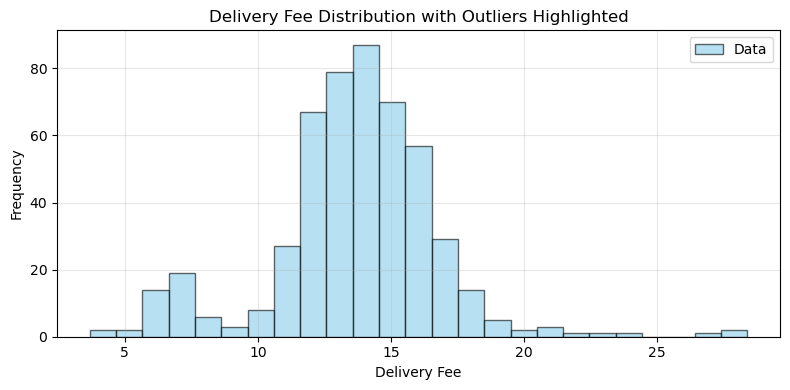

In [35]:
# Plot histogram
plt.figure(figsize=(8, 4))
plt.hist(df_outlier["delivery_fee"], bins=25, alpha=0.6, label="Data", color="skyblue", edgecolor="black")

# Annotate plot
plt.title("Delivery Fee Distribution with Outliers Highlighted")
plt.xlabel("Delivery Fee")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This histogram illustrates the distribution of delivery fees within the dataset. The following observations can be made:

**1. Shape and Central Tendency**

- The distribution appears slightly right-skewed (positively skewed), most delivery fees cluster between 12 and 16, with a gradual decline toward higher values.
- The peak frequency (mode) occurs around 14–15, indicating that most delivery fees fall within this range.
- There are fewer data points on the lower end (below 8) and higher end (above 20).

**2. Spread and Range**

- The delivery fees range roughly from 4 to 27.
- The majority of observations (approximately 90%) lie between 10 and 18, suggesting a relatively consistent pricing pattern with only a few extreme cases.

**3. Outliers**

- A few bars appear far to the right (beyond 22–25), indicating potential outliers with unusually high delivery fees.
- These points could result from data entry errors, unusual distance values, or special pricing conditions.

**4. Variability**

- The data show moderate variability, with a broad but concentrated peak.
- This implies that while most delivery fees are similar, there are occasional deviations worth investigating.

**5. Skewness and Implications**

- The right skewness suggests that while most deliveries are moderately priced, a small number of orders incur higher delivery fees — possibly due to long distances or special conditions.
- For statistical modeling, applying transformations (e.g., log transformation) may help normalize the data if needed.

---

<div class="alert alert-block alert-info">
    
### 6.2. Interquartile Range (IQR) <a class="anchor" name="Outlier_irq"></a>

</div>

In this section, we will detect outliers in the **order_price** column using the **Interquartile Range (IQR)** method. This method calculates the lower and upper bounds of the data, which we can use to filter and identify outliers. Additionally, we will use a box plot to gain a clearer visual understanding of the data distribution and the presence of outliers.

In [36]:
# Compute IQR for order_price
Q1 = df_outlier["delivery_fee"].quantile(0.25)
Q3 = df_outlier["delivery_fee"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect Outliers
distance_outlier_filter = (df_outlier["delivery_fee"] < lower_bound) | (df_outlier["delivery_fee"] > upper_bound)
outliers = df_outlier[distance_outlier_filter]

# Update status
df_outlier.loc[distance_outlier_filter, "status"] =  f'IQR, lower: {round(lower_bound,1)}, upper: {round(upper_bound,1)} '

# Print Summary
print("Delivery Fee Outlier Summary (IQR Method):")
print(f"Q1 = {Q1}")
print(f"Q3 = {Q3}")
print(f"IQR = {IQR}")
print(f"Lower Bound = {lower_bound}")
print(f"Upper Bound = {upper_bound}")
print(f"Total Outliers = {len(outliers)} ({len(outliers)/len(df_outlier)*100:.2f}%)")

# Check output
print("-"*50)
print("Show outlier data (10):")
display(df_outlier.loc[distance_outlier_filter, ['order_id', 'delivery_fee', 'status']].head(10))

Delivery Fee Outlier Summary (IQR Method):
Q1 = 12.324604425
Q3 = 15.3912611
IQR = 3.066656674999999
Lower Bound = 7.724619412500002
Upper Bound = 19.991246112499997
Total Outliers = 48 (9.60%)
--------------------------------------------------
Show outlier data (10):


,order_id,delivery_fee,status
5,ORDC02582,7.094993,"IQR, lower: 7.7, upper: 20.0"
18,ORDJ01040,6.035952,"IQR, lower: 7.7, upper: 20.0"
23,ORDZ08523,20.923088,"IQR, lower: 7.7, upper: 20.0"
26,ORDJ05580,6.859276,"IQR, lower: 7.7, upper: 20.0"
27,ORDJ03678,6.958823,"IQR, lower: 7.7, upper: 20.0"
28,ORDY07576,7.117944,"IQR, lower: 7.7, upper: 20.0"
39,ORDC03039,7.312523,"IQR, lower: 7.7, upper: 20.0"
49,ORDA08148,26.975048,"IQR, lower: 7.7, upper: 20.0"
77,ORDY09931,5.814660,"IQR, lower: 7.7, upper: 20.0"
91,ORDY02376,5.131727,"IQR, lower: 7.7, upper: 20.0"


---

<div class="alert alert-block alert-info">
    
### 6.3. Box Plot <a class="anchor" name="Outlier_box_plot"></a>

</div>

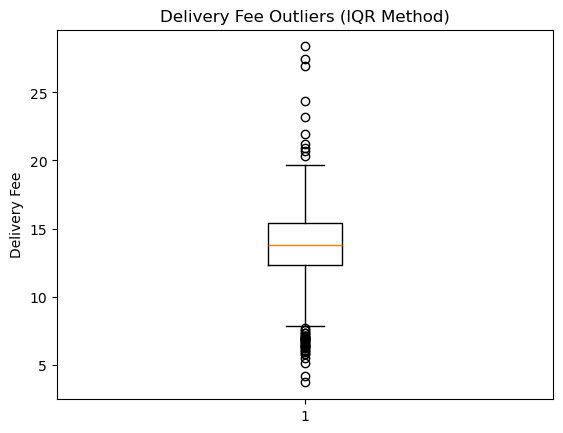

In [37]:
# Show Boxplot
plt.figure()
plt.boxplot(df_outlier["delivery_fee"], vert=True)
plt.title("Delivery Fee Outliers (IQR Method)")
plt.ylabel("Delivery Fee")
plt.show()

---

<div class="alert alert-block alert-info">
    
### 6.4. Delivery Fee Distribution with IQR Outlier <a class="anchor" name="Outlier_dis_iqr"></a>

</div>

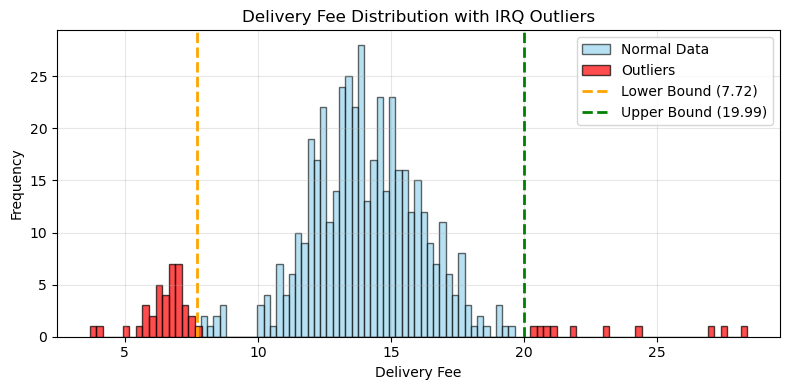

In [38]:
# Split data for plotting
distance_outlier_filter = (df_outlier["delivery_fee"] < lower_bound) | (df_outlier["delivery_fee"] > upper_bound)
outliers = df_outlier[distance_outlier_filter]

normal = df_outlier[~distance_outlier_filter]["delivery_fee"]
outliers = df_outlier[distance_outlier_filter]["delivery_fee"]

# Plot histogram
plt.figure(figsize=(8, 4))
plt.hist(normal, bins=50, alpha=0.6, label="Normal Data", color="skyblue", edgecolor="black")
plt.hist(outliers, bins=100, alpha=0.7, label="Outliers", color="red", edgecolor="black")
plt.axvline(lower_bound, color="orange", linestyle="--", linewidth=2, label=f"Lower Bound ({lower_bound:.2f})")
plt.axvline(upper_bound, color="green", linestyle="--", linewidth=2, label=f"Upper Bound ({upper_bound:.2f})")

# Annotate plot
plt.title("Delivery Fee Distribution with IRQ Outliers")
plt.xlabel("Delivery Fee")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

<div class="alert alert-block alert-info">
    
### 6.5. Z-Score <a class="anchor" name="Outlier_zscore_2"></a>

</div>

In this section, we will use the Z-Score method to identify outliers in the delivery_fee data. We will classify data points with  |Z| > 2.5 as moderate outliers.

In [39]:
# Compute mean, std, and Z-scores
mean_val = df_outlier["delivery_fee"].mean()
std_val = df_outlier["delivery_fee"].std()
df_outlier["z_score"] = (df_outlier["delivery_fee"] - mean_val) / std_val

threshold = 2.5
distance_outlier_filter = np.abs(df_outlier["z_score"]) > threshold

# Update status
df_outlier.loc[distance_outlier_filter, "status"] =  f'Z-Score, mean: {round(mean_val,1)}, std: {round(std_val,1)}, threshold: {threshold} '

# Print Summary
print("Delivery Fee Outlier Summary (Z-Score):")
print(f"Mean = {mean_val}")
print(f"Std = {std_val}")
print(f"threshold = {threshold}")
print(f"Total Outliers = {sum(distance_outlier_filter)} ({sum(distance_outlier_filter)/len(df_outlier)*100:.2f}%)")

# Check output
print("-"*50)
print("Show outlier data (10):")
display(df_outlier.loc[distance_outlier_filter, ['order_id', 'delivery_fee', 'z_score', 'status']])

Delivery Fee Outlier Summary (Z-Score):
Mean = 13.6581541351
Std = 3.136006752535143
threshold = 2.5
Total Outliers = 12 (2.40%)
--------------------------------------------------
Show outlier data (10):


,order_id,delivery_fee,z_score,status
49,ORDA08148,26.975048,4.246449,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
77,ORDY09931,5.814660,-2.501109,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
91,ORDY02376,5.131727,-2.718880,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
154,ORDC09629,21.958305,2.646726,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
173,ORDJ09906,3.686445,-3.179747,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
196,ORDC01712,24.403663,3.426494,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
251,ORDY01225,5.760705,-2.518314,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
320,ORDZ01517,23.173467,3.034213,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
321,ORDA00591,28.379633,4.694339,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"
359,ORDX10264,27.451227,4.398292,"Z-Score, mean: 13.7, std: 3.1, threshold: 2.5"


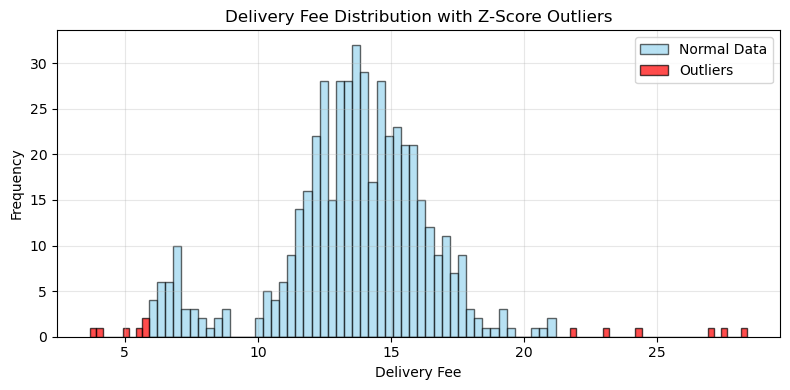

In [40]:
normal = df_outlier[~distance_outlier_filter]["delivery_fee"]
outliers = df_outlier[distance_outlier_filter]["delivery_fee"]

# Plot histogram
plt.figure(figsize=(8, 4))
plt.hist(normal, bins=50, alpha=0.6, label="Normal Data", color="skyblue", edgecolor="black")
plt.hist(outliers, bins=100, alpha=0.7, label="Outliers", color="red", edgecolor="black")

# Annotate plot
plt.title("Delivery Fee Distribution with Z-Score Outliers")
plt.xlabel("Delivery Fee")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-info">
    
### 6.6. Output Outlier Data <a class="anchor" name="Outlier_output"></a>

</div>

After reviewing and validating all columns in the dirty dataset, we can now safely export the cleaned data to Group012_outlier_data_solution.csv.

In [41]:
#Show status of the updated data
print(df_outlier.loc[df_outlier['status'] != 'original', ['order_id', 'status']].to_string())

# Delete non original data
df_outlier = df_outlier[df_outlier['status'] == 'original']

# Drop the column from df_outlier
cols_to_drop = ["z_score", "status"]

df_outlier.drop(columns=cols_to_drop, inplace=True)

      order_id                                          status
5    ORDC02582                   IQR, lower: 7.7, upper: 20.0 
18   ORDJ01040                   IQR, lower: 7.7, upper: 20.0 
23   ORDZ08523                   IQR, lower: 7.7, upper: 20.0 
26   ORDJ05580                   IQR, lower: 7.7, upper: 20.0 
27   ORDJ03678                   IQR, lower: 7.7, upper: 20.0 
28   ORDY07576                   IQR, lower: 7.7, upper: 20.0 
39   ORDC03039                   IQR, lower: 7.7, upper: 20.0 
49   ORDA08148  Z-Score, mean: 13.7, std: 3.1, threshold: 2.5 
77   ORDY09931  Z-Score, mean: 13.7, std: 3.1, threshold: 2.5 
91   ORDY02376  Z-Score, mean: 13.7, std: 3.1, threshold: 2.5 
111  ORDZ01829                   IQR, lower: 7.7, upper: 20.0 
122  ORDC08958                   IQR, lower: 7.7, upper: 20.0 
130  ORDZ05902                   IQR, lower: 7.7, upper: 20.0 
135  ORDA10495                   IQR, lower: 7.7, upper: 20.0 
139  ORDI04133                   IQR, lower: 7.7, upper

In [42]:
output_path = "Group012_outlier_data_solution.csv"
df_outlier.to_csv(output_path, index=False, encoding="utf-8")
print("File saved as:", output_path)

File saved as: Group012_outlier_data_solution.csv
